# Linear models for statistical inference in a designed experiment

**Chris Hallsworth**  
2026-10-04


In [2]:
# Run the notebook cells in order. If needed, install the packages with:
%pip install numpy pandas scipy matplotlib statsmodels openpyxl

Note: you may need to restart the kernel to use updated packages.


# Introduction

In this tutorial, we will see how the linear model is used to analyse experimental data.


In what follows, we will

- Fit a linear model using `statsmodels`' `ols` function and see how to reproduce the output from first principles. 
- Revise confidence intervals using the t-distribution
- Revise the F-test for comparing nested linear models.

The six exercises are numbered. Each exercise links to its worked solution at the end of the notebook; each solution has a link back to the exercise.


# The data
We will use data from a genomics study in fruit fly [Drosophilia Melanogaster](https://en.wikipedia.org/wiki/Drosophila_melanogaster), which is widely used as a model organism.

The study that produced our dataset was investigating the relationship between ageing and diet. We'll focus on just one part of the analysis, comparing the ratio of triglyceride (a type of fat) to protein in flies that have been fed four different diets.

The original study is [here](https://elifesciences.org/articles/59399) but you're not expected to read it: all of the background you need is explained below.

In [3]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7, 4.5), "figure.dpi": 110})

The data file is available on Canvas. If the local file is missing, the code downloads the published source data.

In [4]:
file_path = Path("../data/elife-59399-fig1-data1-v2.xlsx")
if not file_path.exists():
    # Download the published source data if the local file is unavailable.
    file_path.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve(
        "https://cdn.elifesciences.org/articles/59399/elife-59399-fig1-data1-v2.xlsx",
        file_path,
    )

df = pd.read_excel(file_path, sheet_name="H", usecols="A:F", nrows=48)
df.columns = ["diet", "replicate", "weight_mg_fly", "tag_ug_fly",
              "protein_ug_fly", "tag_protein"]
# Explicit ordering preserves the reference group and coefficient order.
diet_levels = ["CD", "FD S24Y3", "FD S30Y3", "FD SY10"]
df["diet"] = pd.Categorical(df["diet"], categories=diet_levels)

To get familiar with the data, evaluate `df` in a notebook cell, or use `df.head()` to view its first few rows.

We see that there are four different conditions (diets) and 12 different biological replicates in each condition. This means $4 \times 12 = 48$ flies were used in the experiment: observations with the same replicate number but different diet are entirely unrelated.

We'll start by making an exploratory plot.

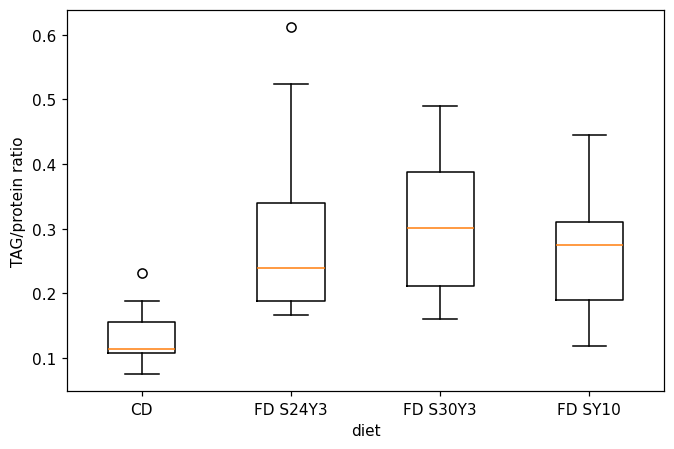

In [5]:
diet_values = [df.loc[df["diet"] == diet, "tag_protein"].to_numpy()
               for diet in diet_levels]
positions = np.arange(1, len(diet_levels) + 1)
fig, ax = plt.subplots()
ax.boxplot(diet_values, positions=positions)
ax.set_xticks(positions, diet_levels)
ax.set(xlabel="diet", ylabel="TAG/protein ratio")
plt.show()

Fig 1H of the article shows a version of this plot, with the individual data points overlaid with a horizontal jitter to make them easier to distinguish, as below

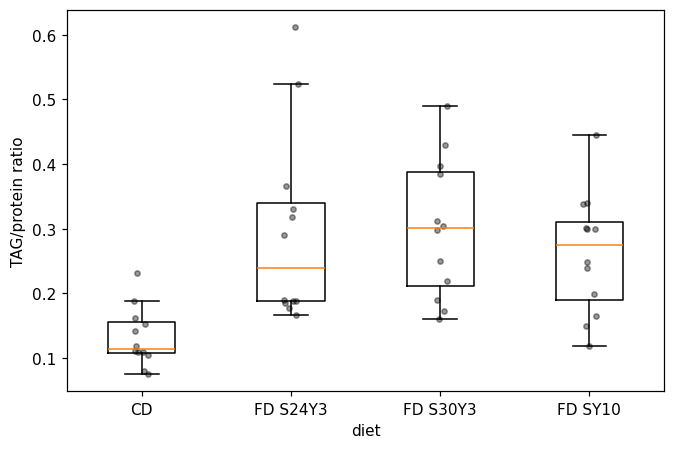

In [6]:
fig, ax = plt.subplots()
ax.boxplot(diet_values, positions=positions, showfliers=False)
rng = np.random.default_rng(555)
for position, values in zip(positions, diet_values):
    jitter = rng.uniform(-0.05, 0.05, size=len(values))
    ax.scatter(position + jitter, values, s=12, color="black", alpha=0.4)
ax.set_xticks(positions, diet_levels)
ax.set(xlabel="diet", ylabel="TAG/protein ratio")
plt.show()

We see that there are three different fixed diet (FD) conditions and one choice diet (CD) condition.



# Specifying models



## The general model

Given the design of the experiment, we start with an unconstrained model that allows for the mean response to be arbitrarily different in the four different conditions.

Since we have an intercept, we need three additional parameters to accommodate four different group means.

We specify this as

$$ y_{i} = \beta_0 + \beta_1 x_{i1} + \beta_{2}x_{i2} + \beta_3 x_{i3} +  \epsilon_{i}, \qquad \epsilon_{i} \sim N(0, \sigma^2), $$
where for $i = 1, 2, \ldots, 48$,


$$
x_{ij} =  \begin{cases} 
  1 \qquad  \text{subject } i \text{ has diet } j \\
  0 \qquad \text{otherwise}
\end{cases}
$$

In this model, the design matrix $X$ is clearly of full rank. We estimate $p_1 = 4$ parameters from the data. There are therefore $n - p_1 = 48 - 4 = 44$ residual degrees of freedom.




## The null model
The null hypothesis is that diet has no effect, so that the all group means are equal. This is specified as

$$ \beta_1 = \beta_2 = \beta_3 = 0. $$
The null model therefore only has an intercept,

$$ y_{i} = \beta_0 + \epsilon_{i}, \qquad \epsilon_{i} \sim N(0, \sigma^2). $$

The null model has $p_0 = 1$ degree of freedom, because a single parameter $\beta_0$ is being estimated from the data. There are therefore
$$n-p_0 = 48 - 1 = 47$$

residual degrees of freedom.

Note that the null model is a nested submodel of the general model.



# Fitting models



## Null model

For simplicity, we start by fitting the intercept-only model in Python as follows.

In [7]:
fit0 = smf.ols("tag_protein ~ 1", data=df).fit()

The output is obtained through the summary

In [8]:
display(fit0.summary())
print(f"Residual standard error: {np.sqrt(fit0.mse_resid):.7f}")

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            tag_protein   R-squared:                      -0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Thu, 29 Oct 2026   Prob (F-statistic):                nan
Time:                        14:23:30   Log-Likelihood:                 33.104
No. Observations:                  48   AIC:                            -64.21
Df Residuals:                      47   BIC:                            -62.34
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2470      0.018     13.948      0.000       0.211       0.283
==============================================================================
Omnibus:                        7.478   Durbin-Watson:                   1.092
Prob(Omnibus):                  0.024   Jarque-Bera (JB):                6.715
Skew:                           0.895   Prob(JB):                       0.0348
Kurtosis:                       3.395   Cond. No.                         1.00
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Residual standard error: 0.1226913


We will now obtain all of these values by hand.

First, we obtain the model matrix. For the intercept-only model, this is simply a single column,

$$
X = \begin{pmatrix}
			 \uparrow  \\
			 1 \\
			 \downarrow 
			 \end{pmatrix}.
$$
We can extract the design matrix $X_0$ from the model object,

In [9]:
X0 = fit0.model.exog

To match with the notation used throughout the module, we'll define the response variable as $y$:

In [10]:
y = df["tag_protein"].to_numpy()

### Exercise 1

On Problem Sheet 1, it is shown that for the null model, $\widehat{\beta}_0$ is just the sample mean $\bar{y}$. Verify the parameter value obtained in the object `fit0` by computing explicitly with `X0` and `y`.

[View solution 1](#Solution-1)


### Exercise 2

Find the residual sum of squares $RSS_0$ for the null model, and use it to verify the residual standard error given in `fit0`.

[View solution 2](#Solution-2)


## General alternative model

Here is the Python code for fitting the general alternative model, in which the four different diets are allowed to have different means.

In [11]:
fit1 = smf.ols("tag_protein ~ diet", data=df).fit()

Note that by default, the syntax `y ~ x` fits a model that includes an intercept parameter as well as including `x` as a covariate.

The model output is

In [12]:
display(fit1.summary())
print(f"Residual standard error: {np.sqrt(fit1.mse_resid):.7f}")

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            tag_protein   R-squared:                       0.316
Model:                            OLS   Adj. R-squared:                  0.270
Method:                 Least Squares   F-statistic:                     6.784
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           0.000738
Time:                        14:23:30   Log-Likelihood:                 42.228
No. Observations:                  48   AIC:                            -76.46
Df Residuals:                      44   BIC:                            -68.97
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.1316      0.030      4.347      0.000       0.071       0.193
diet[T.FD S24Y3]     0.1628      0.043      3.804      0.000       0.077       0.249
diet[T.FD S30Y3]     0.1689      0.043      3.946      0.000       0.083       0.255
diet[T.FD SY10]      0.1300      0.043      3.036      0.004       0.044       0.216
==============================================================================
Omnibus:                        8.189   Durbin-Watson:                   1.632
Prob(Omnibus):                  0.017   Jarque-Bera (JB):                7.216
Skew:                           0.862   Prob(JB):                       0.0271
Kurtosis:                       3.799   Cond. No.                         4.79
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Residual standard error: 0.1048535


***



### Exercise 3

Extract the design matrix as above and compute $\widehat{\beta}$ for the general alternative explicitly. Verify the computed value for the residual standard error.

[View solution 3](#Solution-3)


# Confidence intervals for individual parameters 



### Exercise 4

Recalling that $Var\left(\widehat{\beta}\right) = \sigma^2 (X^T X)^{-1}$, obtain the standard errors for the parameter estimates given in `fit1`. Comment on the standard errors for the three non-intercept parameters.

[View solution 4](#Solution-4)


### Exercise 5

Find a 95% confidence interval for the mean difference between the S24Y3 group and the S30Y3 group. Comment on whether there is evidence for a difference between these groups in the mean response.

[View solution 5](#Solution-5)


# F-test

The F-statistic in the model summary tests the null hypothesis corresponding to the intercept-only model.

The test statistic in this case is

$$ F = \frac{RSS_0 - RSS_1}{RSS_1} \frac{n-p_1}{p_1 - p_0}. $$
All of the relevant quantities are summarized in the **ANOVA table**,

In [13]:
anova_lm(fit0, fit1)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,47.0,0.707498,0.0,NaN,NaN,NaN
1,44.0,0.483748,3.0,0.22375,6.78385,0.000738


***



### Exercise 6

Verify the quantities given in the ANOVA table.

[View solution 6](#Solution-6)


# References

Original study:

Lyu, Yang, et al. "Drosophila serotonin 2A receptor signaling coordinates central metabolic processes to modulate aging in response to nutrient choice." Elife 10 (2021): e59399.

Discussed in:

Walker, Jeffrey, [Applied Biostatistics for Experimental Biology](https://www.middleprofessor.com/files/applied-biostatistics_bookdown/_book/)

# Solutions

Run the notebook cells above before working through these solutions. The solutions are intended to be run in numerical order, since later solutions use quantities calculated in earlier ones.

## Solution 1

For the intercept-only model, $X_0^TX_0$ is just the $1 \times 1$ matrix $(n)$.

In [14]:
X0TX0 = X0.T @ X0
X0TX0

array([[48.]])

Hence $(X_0^T X_0 )^{-1}$ is just $(\frac{1}{n})$

and so

$$ \widehat{\beta_0} = (X_0^T X_0 )^{-1} X_0^T y = \frac{ 1}{n} \sum_{i=1}^n y_i= \bar{y}. $$
Explicitly,

In [15]:
np.mean(y)

np.float64(0.24700191745833333)

This matches the value in `fit0` as expected.



***



[Back to Exercise 1](#Exercise-1)

## Solution 2

The residual sum of squares is then

$$ RSS_0 = \sum_{i=1}^n (y_i - \widehat{y}_0)^2 = \sum_{i=1}^n (y_i - \bar{y})^2   $$
We compute this in Python as the squared length of the vector of residuals

In [16]:
e_hat0 = fit0.resid.to_numpy()
RSS0 = e_hat0 @ e_hat0

The estimate of the residual variance is then

$$ \widehat{\sigma_0}^2 = \frac{RSS_0}{n-p_0}  $$
Explicitly

In [17]:
n = len(df)
sigsq0 = RSS0 / (n - 1)

The residual standard error is

In [18]:
np.sqrt(sigsq0)

np.float64(0.12269128311865368)

which matches the output of `fit0`.


***



[Back to Exercise 2](#Exercise-2)

## Solution 3

We can extract the design matrix $X$ using `fit1.model.exog`.

In [19]:
X = fit1.model.exog

This then allows us to compute $\widehat{\beta}$,

In [20]:
XTX = X.T @ X
beta_hat = np.linalg.solve(XTX, X.T @ y)
beta_hat

array([0.13156499, 0.16284342, 0.1689295 , 0.12997479])

In [21]:
display(fit1.summary())
print(f"Residual standard error: {np.sqrt(fit1.mse_resid):.7f}")

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            tag_protein   R-squared:                       0.316
Model:                            OLS   Adj. R-squared:                  0.270
Method:                 Least Squares   F-statistic:                     6.784
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           0.000738
Time:                        14:23:30   Log-Likelihood:                 42.228
No. Observations:                  48   AIC:                            -76.46
Df Residuals:                      44   BIC:                            -68.97
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.1316      0.030      4.347      0.000       0.071       0.193
diet[T.FD S24Y3]     0.1628      0.043      3.804      0.000       0.077       0.249
diet[T.FD S30Y3]     0.1689      0.043      3.946      0.000       0.083       0.255
diet[T.FD SY10]      0.1300      0.043      3.036      0.004       0.044       0.216
==============================================================================
Omnibus:                        8.189   Durbin-Watson:                   1.632
Prob(Omnibus):                  0.017   Jarque-Bera (JB):                7.216
Skew:                           0.862   Prob(JB):                       0.0271
Kurtosis:                       3.799   Cond. No.                         4.79
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Residual standard error: 0.1048535


The residual sum of squares is

In [22]:
e_hat1 = fit1.resid.to_numpy()
RSS1 = e_hat1 @ e_hat1

There are $p_1 = 4$ model degrees of freedom, so the residual variance estimate is

In [23]:
sigsq1 = RSS1 / (n - 4)

And the residual standard error

In [24]:
np.sqrt(sigsq1)

np.float64(0.10485354740965694)

matching the output of `fit1`.





[Back to Exercise 3](#Exercise-3)

## Solution 4

The variance of $\widehat{\beta}_j$ is the $j$th diagonal entry of $\sigma^2 (X^T X)^{-1}$. The standard error is just the square root of this value. Plugging in the variance estimate gives

In [25]:
np.sqrt(np.diag(np.linalg.inv(XTX)) * sigsq1)

array([0.03026861, 0.04280628, 0.04280628, 0.04280628])

The three non-intercept parameters have equal standard error by symmetry: the design is balanced, i.e. all groups have an equal number of observations, hence equal standard errors.


***



[Back to Exercise 4](#Exercise-4)

## Solution 5

The mean in the S24Y3 group is

$$ E(Y) = \beta_0 + \beta_1 $$
and in the S30Y3 group is

$$ E(Y) = \beta_0 + \beta_2,$$

so the mean difference is $\beta_2 - \beta_1$, which we can write as $c^T \beta$ for $c = (0, -1,1, 0)$.

The maximum likelihood estimate of this difference is

In [26]:
diff_coef = np.array([0, -1, 1, 0])
diff_hat = float(diff_coef @ beta_hat)

Note: `@` denotes matrix multiplication, or an inner product for two one-dimensional NumPy arrays. Here the inner product already returns a scalar; `float` makes the Python scalar type explicit.


This estimate of the difference has sampling variance $\sigma^2 c^T (X^TX)^{-1} c$. We compute this explicitly,

In [27]:
var_diff = (diff_coef @ np.linalg.inv(XTX) @ diff_coef) * sigsq1

The standard error is just the square root of this variance.

In [28]:
se_diff = float(np.sqrt(var_diff))

We need the appropriate quantile of the $t$ distribution with $n-p_1 = n-4$ degrees of freedom

In [29]:
t_val = stats.t.ppf(0.975, df=n - 4)

So that the confidence interval is given by

In [30]:
diff_ci = diff_hat + t_val * se_diff * np.array([-1, 1])
diff_ci

array([-0.08018431,  0.09235647])

[Back to Exercise 5](#Exercise-5)

## Solution 6

Under the null hypothesis the test statistic has the $F(p_1 -p_0, n-p_1)$ distribution. Here we have $p_1 - p_0 = 4 - 1 = 3$ and $n - p_1 = 48 - 4 = 44$, matching the $F(3, 44)$ distribution in the `fit1` output.

In [31]:
F_stat = (RSS0 - RSS1) / RSS1 * (48 - 4) / (4 - 1)
F_stat

np.float64(6.783850320464206)

The corresponding p-value is

In [32]:
stats.f.sf(F_stat, dfn=3, dfd=44)

np.float64(0.0007375672799394278)

This provides strong evidence against the null hypothesis of equal means. This seems reasonable given the plot.


***



[Back to Exercise 6](#Exercise-6)